# JERICHON — Nowcasting: аудит метрик и проверка реального исхода

**Задача:** проверить, действительно ли NCA заранее распознаёт экстремум, а не просто повторяет логику Directional Change.

Предыдущая версия использовала слишком мягкое совпадение события: любой следующий DC-pivot того же типа, расположенный не раньше текущего экстремума, считался успехом. Это могло почти гарантировать `precision ≈ 100%`. В этой версии:
1. Сигнал считается точным только если будущий DC-pivot — **тот же самый бар экстремума**, который был известен на момент сигнала.
2. Дополнительно оцениваем практический исход: достигла ли цена цели в направлении ожидаемого разворота **до** обновления прежнего экстремума.
3. Параметры подбираются только на раннем временном участке; итог проверяется на более позднем.
4. Для каждой конфигурации сохраняются количества сигналов, точность точного pivot, lead time и доля target-before-invalidation.

Это исследовательский аудит, не торговая стратегия. Важно: загруженная история сейчас покрывает примерно месяц, а не целевые 3–6 месяцев. Выводы пока предварительные.

## 0. Конфигурация и импорты

По умолчанию notebook обрабатывает все тикеры, для которых локально найдены trades и три группы Super Candles. Чтобы сначала проверить только два тикера, поменяй `TICKER_MODE` на `"focus"`.

In [1]:
from pathlib import Path
import sys, warnings, json, time, traceback
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss,
    precision_score, recall_score, balanced_accuracy_score
)

TICKER_MODE = "all_available"  # "focus" или "all_available"
FOCUS_TICKERS = ["SMLT", "GAZP", "YDEX", "MTLR", "MAGN"]
DOLLAR_THRESHOLD_DEFAULT = 10_000_000
DOLLAR_THRESHOLD_BY_TICKER = {
    # При необходимости задай отдельный threshold для конкретного инструмента.
    # "GAZP": 20_000_000,
    # "SMLT": 10_000_000,
}
EXPECTED_BASE_FEATURES = 73
EXPECTED_ML_FEATURES = 474

# DC threshold: исследуем несколько масштабов, не выбираем лучший по одному тикеру.
THETAS = [0.005, 0.0075, 0.01, 0.015, 0.02]
P_TMV_GRID = [1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0]
P_BM_GRID = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]
TEST_FRACTION = 0.30
RANDOM_STATE = 42
MIN_EVENTS_FOR_METRICS = 20

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "data" / "for_ml" / "storage" / "history").exists() and (p / "src" / "data" / "builders").exists():
            return p
    fallback = Path(r"C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON")
    if (fallback / "data" / "for_ml" / "storage" / "history").exists():
        return fallback
    raise FileNotFoundError(
        "Не найден корень JERICHON. Открой notebook из папки репозитория "
        "или укажи PROJECT_ROOT вручную в этой ячейке."
    )

PROJECT_ROOT = find_project_root()
DATA_ROOT = PROJECT_ROOT / "data"
HISTORY_ROOT = DATA_ROOT / "for_ml" / "storage" / "history"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Сохраняем именно тот import, который используется в твоём проекте.
from src.data.builders import jerichon_feature_pipeline as jfp

print("PROJECT_ROOT:", PROJECT_ROOT)
print("HISTORY_ROOT:", HISTORY_ROOT)
print("Pipeline module:", jfp.__file__)

PROJECT_ROOT: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON
HISTORY_ROOT: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\storage\history
Pipeline module: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py


## 1. Обнаружение и загрузка локальных источников

В загрузке нет API fallback: если файла нет, он не скачивается автоматически. Дубликаты сделок по timestamp не удаляем — несколько исполнений могут иметь одинаковое время.

In [2]:
SOURCE_KEYS = ("trades", "tradestats", "obstats", "orderstats")

def available_dates(history_root, ticker):
    dates = set()
    for kind in ("realtime", "supercandles"):
        p = history_root / kind / ticker
        if p.exists():
            dates.update(x.name for x in p.iterdir() if x.is_dir())
    return sorted(d for d in dates if len(d) == 10 and d[4] == "-" and d[7] == "-")

def discover_tickers(history_root):
    root = history_root / "realtime"
    if not root.exists():
        return []
    candidates = sorted(p.name for p in root.iterdir() if p.is_dir())
    good = []
    for ticker in candidates:
        dates = available_dates(history_root, ticker)
        has_trades = any((history_root / "realtime" / ticker / d / "trades.parquet").exists() for d in dates)
        has_sc = all(any((history_root / "supercandles" / ticker / d / f"{k}.parquet").exists() for d in dates)
                     for k in ("tradestats", "obstats", "orderstats"))
        if has_trades and has_sc:
            good.append(ticker)
    return good

def load_local_history(history_root, ticker):
    frames = {k: [] for k in ("candles", "trades", "orderbook", "tradestats", "obstats", "orderstats")}
    dates = available_dates(history_root, ticker)
    if not dates:
        raise FileNotFoundError(f"Нет сохранённых дат для {ticker}")
    for day in dates:
        for key in ("candles", "trades", "orderbook"):
            path = history_root / "realtime" / ticker / day / f"{key}.parquet"
            if path.exists():
                try:
                    x = pd.read_parquet(path)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as exc:
                    print(f"WARNING read {path}: {exc}")
        for key in ("tradestats", "obstats", "orderstats"):
            path = history_root / "supercandles" / ticker / day / f"{key}.parquet"
            if path.exists():
                try:
                    x = pd.read_parquet(path)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as exc:
                    print(f"WARNING read {path}: {exc}")
    data = {k: pd.concat(v, ignore_index=True) if v else pd.DataFrame() for k, v in frames.items()}
    missing = [k for k in SOURCE_KEYS if data[k].empty]
    if missing:
        raise RuntimeError(f"{ticker}: отсутствуют обязательные источники {missing}")
    return data, dates

AVAILABLE_TICKERS = discover_tickers(HISTORY_ROOT)
print("Локально доступные тикеры:", AVAILABLE_TICKERS)
if TICKER_MODE == "focus":
    TICKERS = [t for t in FOCUS_TICKERS if t in AVAILABLE_TICKERS]
    missing_focus = [t for t in FOCUS_TICKERS if t not in AVAILABLE_TICKERS]
    if missing_focus:
        print("Не найдены локально:", missing_focus)
else:
    # В первую очередь запускаем знакомые SMLT и GAZP, затем остальные.
    TICKERS = [t for t in FOCUS_TICKERS if t in AVAILABLE_TICKERS] + [
        t for t in AVAILABLE_TICKERS if t not in FOCUS_TICKERS
    ]
print("План запуска:", TICKERS)
if not TICKERS:
    raise RuntimeError("Нет тикеров с полным набором локальных источников.")

Локально доступные тикеры: ['AFLT', 'ALRS', 'GAZP', 'GMKN', 'LKOH', 'MAGN', 'MGNT', 'MTLR', 'NVTK', 'PLZL', 'ROSN', 'RUAL', 'SBER', 'SMLT', 'SPBE', 'T', 'TATN', 'VTBR', 'YDEX']
План запуска: ['SMLT', 'GAZP', 'YDEX', 'MTLR', 'MAGN', 'AFLT', 'ALRS', 'GMKN', 'LKOH', 'MGNT', 'NVTK', 'PLZL', 'ROSN', 'RUAL', 'SBER', 'SPBE', 'T', 'TATN', 'VTBR']


## 2. Сборка признаков через канонический JERICHON pipeline

Внутренний helper `_build_sc_features()` использует `ts` и `CLOSE`, поэтому передаём ему отдельную копию bars с этими алиасами. Исходный `bars` оставляем нетронутым. Это исправляет `KeyError: ['ts', 'CLOSE']`.

Предупреждения о фрагментации не отключаются глобально. Мы оборачиваем вызов `_base()` локальным фильтром именно для этого известного предупреждения и сразу делаем `.copy()`. Это убирает шум в выводе, но настоящая оптимизация вставки сотен колонок потребует отдельно переписать `_base()` в `jerichon_feature_pipeline.py`.

In [3]:
def build_feature_dataset(ticker, data):
    required_helpers = ("build_dollar_bars_from_trades", "_base", "_build_sc_features", "_attach_source")
    missing = [name for name in required_helpers if not hasattr(jfp, name)]
    if missing:
        raise RuntimeError(f"В jerichon_feature_pipeline.py отсутствуют helper-функции: {missing}")

    threshold = DOLLAR_THRESHOLD_BY_TICKER.get(ticker, DOLLAR_THRESHOLD_DEFAULT)
    bars = jfp.build_dollar_bars_from_trades(data["trades"], threshold=threshold)
    if bars is None or bars.empty:
        raise RuntimeError(f"{ticker}: Dollar Bar builder вернул пустой результат.")

    bars = bars.copy()
    # Нормализуем время и OHLC, не удаляя дубликаты сделок до построения баров.
    if "bar_ts" not in bars.columns:
        if "close_time" in bars.columns:
            bars["bar_ts"] = pd.to_datetime(bars["close_time"], errors="coerce", utc=True)
        elif "ts" in bars.columns:
            bars["bar_ts"] = pd.to_datetime(bars["ts"], errors="coerce", utc=True)
        else:
            raise RuntimeError(f"{ticker}: нет bar_ts/close_time/ts. Колонки: {list(bars.columns)}")
    else:
        bars["bar_ts"] = pd.to_datetime(bars["bar_ts"], errors="coerce", utc=True)
    bars = bars.dropna(subset=["bar_ts"]).sort_values("bar_ts").reset_index(drop=True)

    # Поддерживаем стандартные названия OHLC, но не перезаписываем существующие.
    aliases = {
        "open": ("OPEN", "open_price", "OPEN_PRICE"),
        "high": ("HIGH", "high_price", "HIGH_PRICE"),
        "low": ("LOW", "low_price", "LOW_PRICE"),
        "close": ("CLOSE", "close_price", "CLOSE_PRICE"),
        "volume": ("VOLUME", "qty", "volume_qty"),
    }
    for target, options in aliases.items():
        if target not in bars.columns:
            source = next((c for c in options if c in bars.columns), None)
            if source:
                bars[target] = bars[source]
    for col in ("open", "high", "low", "close"):
        if col not in bars.columns:
            raise RuntimeError(f"{ticker}: в Dollar Bars нет {col}; колонки={list(bars.columns)}")

    # Известный PerformanceWarning внутри _base; не подавляем остальные предупреждения.
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="DataFrame is highly fragmented", category=pd.errors.PerformanceWarning)
        base_frame = jfp._base(bars.copy())
    base_frame = base_frame.copy()
    if "bar_ts" not in base_frame.columns:
        if len(base_frame) != len(bars):
            raise RuntimeError(f"{ticker}: _base без bar_ts и изменил число строк.")
        base_frame["bar_ts"] = bars["bar_ts"].to_numpy()
    base_cols = [c for c in base_frame.columns if c.startswith("base__")]
    if not base_cols:
        excluded = {"bar_ts", "bar_ts_utc", "ts", "ts_utc", "close_time"}
        base_cols = [c for c in base_frame.columns if c not in excluded and pd.api.types.is_numeric_dtype(base_frame[c])]
    if len(base_cols) != EXPECTED_BASE_FEATURES:
        raise RuntimeError(f"{ticker}: base inventory {len(base_cols)}, ожидалось {EXPECTED_BASE_FEATURES}")

    # Ключевой фикс KeyError: helper ожидает ts и CLOSE.
    bars_for_sc = bars.copy()
    if "ts" not in bars_for_sc.columns:
        bars_for_sc["ts"] = bars_for_sc["bar_ts"]
    if "CLOSE" not in bars_for_sc.columns:
        bars_for_sc["CLOSE"] = bars_for_sc["close"]

    raw_sc = {k: data[k] for k in ("tradestats", "obstats", "orderstats")}
    sc_frames = jfp._build_sc_features(raw_sc, bars_for_sc)
    if not isinstance(sc_frames, dict):
        raise TypeError(f"{ticker}: _build_sc_features вернул {type(sc_frames)}, ожидался dict.")

    causal = bars[["bar_ts"]].copy()
    for source in ("tradestats", "obstats", "orderstats"):
        if source not in sc_frames or sc_frames[source] is None or sc_frames[source].empty:
            raise RuntimeError(f"{ticker}: нет feature frame для {source}")
        causal = jfp._attach_source(causal, sc_frames[source], data[source], source)
        if causal is None or causal.empty:
            raise RuntimeError(f"{ticker}: _attach_source вернул пустой результат для {source}")

    base_frame["bar_ts"] = pd.to_datetime(base_frame["bar_ts"], errors="coerce", utc=True)
    causal["bar_ts"] = pd.to_datetime(causal["bar_ts"], errors="coerce", utc=True)
    causal = causal.merge(base_frame, on="bar_ts", how="left", validate="one_to_one")

    provenance_cols = [c for c in causal.columns if c.endswith("__event_ts") or c.endswith("__available_at")]
    sc_prefixes = ("tradestats__", "obstats__", "orderstats__")
    sc_cols = [c for c in causal.columns
               if c.startswith(sc_prefixes) and c not in provenance_cols
               and pd.api.types.is_numeric_dtype(causal[c])]
    feature_cols = base_cols + sc_cols
    if len(feature_cols) != EXPECTED_ML_FEATURES:
        raise RuntimeError(f"{ticker}: ML inventory {len(feature_cols)}, ожидалось {EXPECTED_ML_FEATURES}")

    dataset = causal[["bar_ts"] + feature_cols + provenance_cols].copy()
    dataset = dataset.sort_values("bar_ts").reset_index(drop=True)
    market = bars[["bar_ts", "open", "high", "low", "close"]].copy()
    market["bar_ts"] = pd.to_datetime(market["bar_ts"], utc=True)
    market = market.merge(dataset[["bar_ts"] + feature_cols], on="bar_ts", how="inner", validate="one_to_one")
    market = market.sort_values("bar_ts").reset_index(drop=True)
    return bars, market, dataset, feature_cols, threshold

## 3. Каузальное состояние Directional Change и индикаторы NCA

Мы считаем состояние тренда последовательно, только из уже известных закрытий. Для каждого бара фиксируем:
- направление текущего DC-тренда;
- точку старта тренда;
- текущий экстремум;
- `aTMV`: насколько далеко цена ушла от начала тренда в единицах `theta`;
- `BM`: насколько цена откатила от текущего экстремума в единицах `theta`;
- возраст тренда и расстояние до подтверждения DC.

`BM >= 1` означает, что откат уже достиг DC-порога. Поэтому nowcast разрешён только при `P_BM <= BM < 1`. Сигнал не должен задним числом появляться на баре подтверждения.

In [4]:
def causal_dc_state(close, theta):
    p = np.asarray(close, dtype=float)
    n = len(p)
    state = pd.DataFrame(index=np.arange(n), data={
        "trend": np.zeros(n, dtype=int),
        "anchor_idx": np.full(n, -1, dtype=int),
        "anchor_price": np.full(n, np.nan),
        "extreme_idx": np.full(n, -1, dtype=int),
        "extreme_price": np.full(n, np.nan),
        "aTMV": np.full(n, np.nan),
        "BM": np.full(n, np.nan),
        "bars_since_anchor": np.full(n, np.nan),
    })
    if n < 3:
        return state

    # До первого DC-перехода держим начальные high/low.
    trend = 0
    low_i = high_i = 0
    low_p = high_p = p[0]
    anchor_i, anchor_p = 0, p[0]
    extreme_i, extreme_p = 0, p[0]

    for i in range(1, n):
        x = p[i]
        if not np.isfinite(x) or x <= 0:
            continue

        if trend == 0:
            if x < low_p:
                low_p, low_i = x, i
            if x > high_p:
                high_p, high_i = x, i
            if x >= low_p * (1 + theta):
                trend, anchor_i, anchor_p = 1, low_i, low_p
                extreme_i, extreme_p = i, x
            elif x <= high_p * (1 - theta):
                trend, anchor_i, anchor_p = -1, high_i, high_p
                extreme_i, extreme_p = i, x
        elif trend == 1:
            if x > extreme_p:
                extreme_i, extreme_p = i, x
            bm = (extreme_p - x) / (extreme_p * theta)
            if bm >= 1:
                # Разворот подтверждён на текущем баре: новый нисходящий тренд.
                trend = -1
                anchor_i, anchor_p = extreme_i, extreme_p
                extreme_i, extreme_p = i, x
            else:
                state.loc[i, ["trend", "anchor_idx", "anchor_price", "extreme_idx", "extreme_price",
                              "aTMV", "BM", "bars_since_anchor"]] = [
                    trend, anchor_i, anchor_p, extreme_i, extreme_p,
                    abs(extreme_p - anchor_p) / (anchor_p * theta),
                    bm, i - anchor_i
                ]
        else:
            if x < extreme_p:
                extreme_i, extreme_p = i, x
            bm = (x - extreme_p) / (extreme_p * theta)
            if bm >= 1:
                trend = 1
                anchor_i, anchor_p = extreme_i, extreme_p
                extreme_i, extreme_p = i, x
            else:
                state.loc[i, ["trend", "anchor_idx", "anchor_price", "extreme_idx", "extreme_price",
                              "aTMV", "BM", "bars_since_anchor"]] = [
                    trend, anchor_i, anchor_p, extreme_i, extreme_p,
                    abs(extreme_p - anchor_p) / (anchor_p * theta),
                    bm, i - anchor_i
                ]
    return state

def dc_events_from_close(close, theta):
    """Ретроспективные pivots и момент подтверждения по close; только для оценки."""
    p = np.asarray(close, dtype=float)
    rows = []
    if len(p) < 3:
        return pd.DataFrame(columns=["pivot_idx","confirm_idx","side","pivot_price"])
    direction = 0
    hi_i = lo_i = 0
    hi_p = lo_p = p[0]
    pivot_i, pivot_p = 0, p[0]
    for i in range(1, len(p)):
        x = p[i]
        if not np.isfinite(x) or x <= 0:
            continue
        if direction == 0:
            if x < lo_p: lo_p, lo_i = x, i
            if x > hi_p: hi_p, hi_i = x, i
            if x >= lo_p * (1 + theta):
                direction, pivot_i, pivot_p = 1, lo_i, lo_p
                hi_i, hi_p = i, x
            elif x <= hi_p * (1 - theta):
                direction, pivot_i, pivot_p = -1, hi_i, hi_p
                lo_i, lo_p = i, x
        elif direction == 1:
            if x > hi_p: hi_p, hi_i = x, i
            if x <= hi_p * (1 - theta):
                rows.append({"pivot_idx": hi_i, "confirm_idx": i, "side": "peak", "pivot_price": hi_p})
                direction, lo_i, lo_p = -1, i, x
        else:
            if x < lo_p: lo_p, lo_i = x, i
            if x >= lo_p * (1 + theta):
                rows.append({"pivot_idx": lo_i, "confirm_idx": i, "side": "trough", "pivot_price": lo_p})
                direction, hi_i, hi_p = 1, i, x
    return pd.DataFrame(rows)

## 4. Сигнал и строгая проверка идентичности экстремума

Сигнал возникает во время отката, до подтверждения DC. Проверяем две разные гипотезы:

- **H1 — раннее распознавание pivot:** будущий подтверждённый DC-pivot должен совпасть с текущим `extreme_idx`. Если после сигнала цена обновила экстремум, ранний сигнал считается ошибочным.
- **H2 — практический результат:** после сигнала цена достигает цели в направлении разворота до того, как обновит экстремум, который мы пытались распознать.

H1 — строгая event-level метрика. H2 — более прикладная, но всё ещё без комиссий, спреда и модели исполнения.

In [5]:
def generate_nca_signals(state, p_tmv, p_bm, close):
    signals = []
    signaled_legs = set()
    for i, row in state.iterrows():
        trend = int(row["trend"])
        a, bm = row["aTMV"], row["BM"]
        if trend == 0 or not np.isfinite(a) or not np.isfinite(bm):
            continue
        leg_key = (trend, int(row["anchor_idx"]))
        condition = (a >= p_tmv) and (bm >= p_bm) and (bm < 1.0)
        if condition and leg_key not in signaled_legs:
            pivot_idx = int(row["extreme_idx"])
            signals.append({
                "signal_idx": int(i), "trend": trend,
                "anchor_idx": int(row["anchor_idx"]),
                "pivot_idx_at_signal": pivot_idx,
                "pivot_price_at_signal": float(row["extreme_price"]),
                "signal_price": float(close.iloc[i]),
                "aTMV": float(a), "BM": float(bm),
                "bars_since_anchor": float(row["bars_since_anchor"]),
                "predicted_reversal_direction": -trend,
            })
            signaled_legs.add(leg_key)
    return pd.DataFrame(signals)


def score_nca_events(close, state, events, p_tmv, p_bm, max_horizon=50,
                     targets=(0.005, 0.01, 0.015, 0.02)):
    close = pd.Series(close).astype(float).reset_index(drop=True)
    sig = generate_nca_signals(state, p_tmv, p_bm, close)
    if sig.empty:
        return sig, {"signals": 0, "observed_signals": 0, "matched": 0,
                     "precision": np.nan, "median_lead_bars": np.nan,
                     "median_distance_from_pivot_%": np.nan}
    ev = events.sort_values("confirm_idx").reset_index(drop=True)
    scored = []
    for s in sig.to_dict("records"):
        next_events = ev[ev["confirm_idx"] > s["signal_idx"]]
        if len(next_events):
            e = next_events.iloc[0]
            observed = True
            # Строго: тот же экстремум, а не просто следующий pivot того же типа.
            side_expected = "peak" if s["trend"] == 1 else "trough"
            matched = (e["side"] == side_expected and
                       int(e["pivot_idx"]) == int(s["pivot_idx_at_signal"]))
            lead = int(e["confirm_idx"] - s["signal_idx"])
            dist = abs(float(s["signal_price"]) - float(e["pivot_price"])) / float(e["pivot_price"]) * 100
            confirm_idx = int(e["confirm_idx"])
            pivot_idx = int(e["pivot_idx"])
            future_pivot_price = float(e["pivot_price"])
        else:
            observed, matched, lead, dist = False, False, np.nan, np.nan
            confirm_idx, pivot_idx, future_pivot_price = np.nan, np.nan, np.nan

        row = {**s, "observed": observed, "matched": matched,
               "lead_bars": lead, "distance_from_pivot_%": dist,
               "matched_confirm_idx": confirm_idx,
               "matched_pivot_idx": pivot_idx,
               "future_pivot_price": future_pivot_price}

        # Практический outcome: цель в направлении разворота должна быть достигнута
        # раньше, чем цена обновит pivot, который был известен в момент сигнала.
        start = int(s["signal_idx"]) + 1
        stop = min(len(close), int(s["signal_idx"]) + max_horizon + 1)
        fut = close.iloc[start:stop].to_numpy(dtype=float)
        if len(fut):
            direction = int(s["predicted_reversal_direction"])
            entry = float(s["signal_price"])
            pivot_price = float(s["pivot_price_at_signal"])
            for h in (5, 10, 25, 50):
                segment = close.iloc[start:min(stop, int(s["signal_idx"]) + h + 1)].to_numpy(dtype=float)
                if len(segment) == 0:
                    row[f"target_before_invalidation_{h}b_0.5%"] = np.nan
                    row[f"target_before_invalidation_{h}b_1.0%"] = np.nan
                    row[f"target_before_invalidation_{h}b_1.5%"] = np.nan
                    row[f"target_before_invalidation_{h}b_2.0%"] = np.nan
                    continue
                directional_returns = direction * (segment / entry - 1.0)
                # Продолжение исходного тренда за прежний экстремум инвалидирует сигнал.
                if s["trend"] == 1:
                    invalid = segment > pivot_price
                else:
                    invalid = segment < pivot_price
                for target in targets:
                    hit_idx = next((j for j, v in enumerate(directional_returns) if v >= target), None)
                    invalid_idx = next((j for j, v in enumerate(invalid) if bool(v)), None)
                    success = (hit_idx is not None and
                               (invalid_idx is None or hit_idx < invalid_idx))
                    row[f"target_before_invalidation_{h}b_{target*100:.1f}%"] = int(success)
        else:
            for h in (5, 10, 25, 50):
                for target in targets:
                    row[f"target_before_invalidation_{h}b_{target*100:.1f}%"] = np.nan
        scored.append(row)

    scored = pd.DataFrame(scored)
    obs = scored[scored["observed"]]
    return scored, {
        "signals": len(scored),
        "observed_signals": len(obs),
        "matched": int(obs["matched"].sum()) if len(obs) else 0,
        "precision": float(obs["matched"].mean()) if len(obs) else np.nan,
        "median_lead_bars": float(obs.loc[obs.matched, "lead_bars"].median())
            if len(obs) and obs.matched.any() else np.nan,
        "median_distance_from_pivot_%": float(obs.loc[obs.matched, "distance_from_pivot_%"].median())
            if len(obs) and obs.matched.any() else np.nan,
    }

## 5. Поиск параметров без подглядывания в test

Параметры `P_TMV` и `P_BM` выбираются на train по строгому совпадению pivot, при минимуме 20 наблюдаемых сигналов. Затем выбранная конфигурация оценивается на test. Также сохраняем фиксированный baseline (`P_TMV=1.0`, `P_BM=0.1`), чтобы не сравнивать только оптимизированный вариант.

Важно: даже строгая метрика может быть нестабильной при малом числе сигналов. Поэтому рядом всегда смотрим размер выборки и target-before-invalidation.

In [6]:
def evaluate_nca_grid(close, theta, test_fraction=TEST_FRACTION):
    close = pd.Series(close).astype(float).reset_index(drop=True)
    n = len(close)
    split = int(n * (1 - test_fraction))
    if split < 100 or n - split < 50:
        return pd.DataFrame(), {"status": "insufficient rows", "n": n}

    state = causal_dc_state(close, theta)
    events = dc_events_from_close(close, theta)
    rows = []
    for p_tmv in P_TMV_GRID:
        for p_bm in P_BM_GRID:
            scored, _ = score_nca_events(close, state, events, p_tmv, p_bm)
            # У train должны быть известны исходы до split; события через границу исключаем.
            train_sig = scored[(scored.signal_idx < split) & scored.observed &
                               (scored.matched_confirm_idx < split)] if len(scored) else scored
            # Test-сигнал оценивается только если исход наблюдаем в имеющейся истории.
            test_sig = scored[(scored.signal_idx >= split) & scored.observed] if len(scored) else scored
            tr_prec = float(train_sig.matched.mean()) if len(train_sig) else np.nan
            te_prec = float(test_sig.matched.mean()) if len(test_sig) else np.nan
            target_col = "target_before_invalidation_25b_1.0%"
            rows.append({
                "theta": theta, "P_TMV": p_tmv, "P_BM": p_bm,
                "train_observed_signals": len(train_sig),
                "train_matched": int(train_sig.matched.sum()) if len(train_sig) else 0,
                "train_precision_exact_pivot": tr_prec,
                "test_observed_signals": len(test_sig),
                "test_matched": int(test_sig.matched.sum()) if len(test_sig) else 0,
                "test_precision_exact_pivot": te_prec,
                "test_median_lead_bars": float(test_sig.loc[test_sig.matched, "lead_bars"].median())
                    if len(test_sig) and test_sig.matched.any() else np.nan,
                "test_median_distance_from_pivot_%": float(test_sig.loc[test_sig.matched, "distance_from_pivot_%"].median())
                    if len(test_sig) and test_sig.matched.any() else np.nan,
                "test_target1pct_before_invalidation_25b": float(test_sig[target_col].mean())
                    if len(test_sig) and target_col in test_sig else np.nan,
            })
    grid = pd.DataFrame(rows)
    eligible = grid[(grid.train_observed_signals >= MIN_EVENTS_FOR_METRICS) &
                    grid.train_precision_exact_pivot.notna()]
    if eligible.empty:
        return grid, {"status": "no eligible train configuration", "split_idx": split, "n": n}

    # Tie-breaker favours more train observations; all selection occurs on train only.
    best = eligible.sort_values(
        ["train_precision_exact_pivot", "train_observed_signals"],
        ascending=[False, False]
    ).iloc[0].to_dict()
    selected = grid[(grid.P_TMV == best["P_TMV"]) & (grid.P_BM == best["P_BM"])].iloc[0].to_dict()
    baseline = grid[(grid.P_TMV == 1.0) & (grid.P_BM == 0.1)].iloc[0].to_dict()
    summary = {
        "status": "ok", "n": n, "split_idx": split,
        "theta": theta, "selected_P_TMV": best["P_TMV"], "selected_P_BM": best["P_BM"],
        "train_signals": best["train_observed_signals"],
        "train_precision_exact_pivot": best["train_precision_exact_pivot"],
        "test_signals": selected["test_observed_signals"],
        "test_matched": selected["test_matched"],
        "test_precision_exact_pivot": selected["test_precision_exact_pivot"],
        "test_median_lead_bars": selected["test_median_lead_bars"],
        "test_median_distance_from_pivot_%": selected["test_median_distance_from_pivot_%"],
        "test_target1pct_before_invalidation_25b": selected["test_target1pct_before_invalidation_25b"],
        "baseline_P_TMV": 1.0, "baseline_P_BM": 0.1,
        "baseline_test_signals": baseline["test_observed_signals"],
        "baseline_test_precision_exact_pivot": baseline["test_precision_exact_pivot"],
        "baseline_test_target1pct_before_invalidation_25b": baseline["test_target1pct_before_invalidation_25b"],
    }
    return grid, summary

## 6. Запуск по тикерам и порогам DC

Этот этап не объединяет все инструменты в одну модель. Каждый тикер сначала оценивается отдельно: разные ликвидность, волатильность и структура баров могут приводить к разным рабочим параметрам. В таблицах сохраняем тикер, фактическое число баров, даты и Dollar Bar threshold.

In [7]:
all_grids, all_summaries, all_dc_profiles, all_errors, all_signal_details = [], [], [], [], []

for ticker in TICKERS:
    started = time.time()
    print(f"\n{'='*24} {ticker} {'='*24}")
    try:
        data, saved_dates = load_local_history(HISTORY_ROOT, ticker)
        bars, market, dataset, feature_cols, threshold = build_feature_dataset(ticker, data)
        close = market["close"].astype(float).reset_index(drop=True)
        print(f"{ticker}: rows={len(market):,}, features={len(feature_cols)}, "
              f"dates={saved_dates[0]}..{saved_dates[-1]}, dollar_threshold={threshold:,}")

        for theta in THETAS:
            state = causal_dc_state(close, theta)
            events = dc_events_from_close(close, theta)
            grid, summary = evaluate_nca_grid(close, theta)
            summary.update({
                "ticker": ticker, "theta_%": theta * 100,
                "start_date": str(market.bar_ts.min()),
                "end_date": str(market.bar_ts.max()),
                "n_bars": len(market), "dollar_threshold": threshold,
                "dc_events": len(events),
            })
            all_summaries.append(summary)
            if len(grid):
                grid["ticker"], grid["n_bars"] = ticker, len(market)
                all_grids.append(grid)

            # Исправленная диагностика размера движения: pivot сравнивается с anchor,
            # а не с close на самом pivot-баре (что всегда давало бы ноль).
            if len(events):
                valid_events = events[
                    (events.pivot_idx >= 0) & (events.pivot_idx < len(close))
                ].copy()
                anchor_prices = close.iloc[valid_events.pivot_idx.to_numpy()].to_numpy()
                # Амплитуда от предыдущего DC-pivot до текущего pivot; для первого события
                # это оценка от начала ряда, поэтому первый event отдельно исключаем.
                if len(valid_events) > 1:
                    piv = valid_events.pivot_price.to_numpy(dtype=float)
                    leg = np.abs(piv[1:] / piv[:-1] - 1.0) * 100
                    median_leg = float(np.nanmedian(leg))
                else:
                    median_leg = np.nan
            else:
                median_leg = np.nan
            all_dc_profiles.append({
                "ticker": ticker, "theta_%": theta * 100,
                "events": len(events),
                "peaks": int((events.side == "peak").sum()) if len(events) else 0,
                "troughs": int((events.side == "trough").sum()) if len(events) else 0,
                "median_confirmation_delay_bars": float((events.confirm_idx-events.pivot_idx).median()) if len(events) else np.nan,
                "median_abs_pivot_to_pivot_return_%": median_leg,
            })

            # Детальная таблица сигналов для выбранной train-конфигурации.
            if summary.get("status") == "ok":
                chosen = score_nca_events(
                    close, state, events,
                    float(summary["selected_P_TMV"]), float(summary["selected_P_BM"])
                )[0]
                if len(chosen):
                    chosen["ticker"], chosen["theta_%"] = ticker, theta * 100
                    chosen["selected_P_TMV"] = summary["selected_P_TMV"]
                    chosen["selected_P_BM"] = summary["selected_P_BM"]
                    chosen["split_idx"] = summary["split_idx"]
                    chosen["split_role"] = np.where(chosen.signal_idx < summary["split_idx"], "train", "test")
                    all_signal_details.append(chosen)
        print(f"Completed {ticker} in {time.time()-started:.1f}s")
    except Exception as exc:
        all_errors.append({"ticker": ticker, "error": repr(exc), "traceback": traceback.format_exc()})
        print(f"FAILED {ticker}: {exc}")

summary_df = pd.DataFrame(all_summaries)
grid_df = pd.concat(all_grids, ignore_index=True) if all_grids else pd.DataFrame()
dc_profile_df = pd.DataFrame(all_dc_profiles)
errors_df = pd.DataFrame(all_errors)
signal_details_df = pd.concat(all_signal_details, ignore_index=True) if all_signal_details else pd.DataFrame()

display(summary_df)
display(dc_profile_df)
if not errors_df.empty:
    display(errors_df[["ticker", "error"]])


======================== SMLT ========================


C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:77: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_ma{w}"] = mean
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:71: PerformanceWarning: DataFrame is highly fragmented.  Thi

SMLT: rows=2,907, features=474, dates=2026-09-25..2026-10-23, dollar_threshold=10,000,000
Completed SMLT in 112.3s

======================== GAZP ========================


C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:77: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_ma{w}"] = mean
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:71: PerformanceWarning: DataFrame is highly fragmented.  Thi

GAZP: rows=11,566, features=474, dates=2026-09-24..2026-10-23, dollar_threshold=10,000,000
Completed GAZP in 342.8s

======================== YDEX ========================


C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:77: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_ma{w}"] = mean
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:71: PerformanceWarning: DataFrame is highly fragmented.  Thi

... (31 outputs left out)

C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:77: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_ma{w}"] = mean
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:71: PerformanceWarning: DataFrame is highly fragmented.  Thi

VTBR: rows=9,835, features=474, dates=2026-08-28..2026-10-23, dollar_threshold=10,000,000
Completed VTBR in 391.5s


,status,n,split_idx,theta,selected_P_TMV,selected_P_BM,train_signals,train_precision_exact_pivot,test_signals,test_matched,...,baseline_test_signals,baseline_test_precision_exact_pivot,baseline_test_target1pct_before_invalidation_25b,ticker,theta_%,start_date,end_date,n_bars,dollar_threshold,dc_events
0,ok,2907,2034,0.0050,2.00,0.8,64.0,0.796875,24.0,16.0,...,84.0,0.476190,0.250000,SMLT,0.50,2026-09-25 04:03:05+00:00,2026-10-23 19:50:54+00:00,2907,10000000,323
1,ok,2907,2034,0.0075,1.25,0.8,58.0,0.810345,27.0,23.0,...,61.0,0.409836,0.245902,SMLT,0.75,2026-09-25 04:03:05+00:00,2026-10-23 19:50:54+00:00,2907,10000000,216
2,ok,2907,2034,0.0100,1.00,0.8,68.0,0.808824,33.0,28.0,...,42.0,0.380952,0.333333,SMLT,1.00,2026-09-25 04:03:05+00:00,2026-10-23 19:50:54+00:00,2907,10000000,142
3,ok,2907,2034,0.0150,1.75,0.8,23.0,0.826087,13.0,10.0,...,21.0,0.380952,0.380952,SMLT,1.50,2026-09-25 04:03:05+00:00,2026-10-23 19:50:54+00:00,2907,10000000,62
4,ok,2907,2034,0.0200,1.25,0.8,20.0,0.850000,9.0,7.0,...,12.0,0.333333,0.416667,SMLT,2.00,2026-09-25 04:03:05+00:00,2026-10-23 19:50:54+00:00,2907,10000000,43
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
90,ok,9835,6884,0.0050,1.50,0.8,108.0,0.842593,44.0,40.0,...,83.0,0.325301,0.000000,VTBR,0.50,2026-08-28 04:02:32+00:00,2026-10-23 19:53:02+00:00,9835,10000000,411
91,ok,9835,6884,0.0075,2.00,0.8,38.0,0.921053,13.0,11.0,...,44.0,0.295455,0.068182,VTBR,0.75,2026-08-28 04:02:32+00:00,2026-10-23 19:53:02+00:00,9835,10000000,256
92,ok,9835,6884,0.0100,1.50,0.8,41.0,0.804878,13.0,11.0,...,20.0,0.250000,0.050000,VTBR,1.00,2026-08-28 04:02:32+00:00,2026-10-23 19:53:02+00:00,9835,10000000,172
93,ok,9835,6884,0.0150,1.00,0.8,44.0,0.818182,9.0,7.0,...,9.0,0.111111,0.000000,VTBR,1.50,2026-08-28 04:02:32+00:00,2026-10-23 19:53:02+00:00,9835,10000000,78


,ticker,theta_%,events,peaks,troughs,median_confirmation_delay_bars,median_abs_pivot_to_pivot_return_%
0,SMLT,0.50,323,161,162,3.0,1.129503
1,SMLT,0.75,216,108,108,5.0,1.426174
2,SMLT,1.00,142,71,71,8.0,1.828299
3,SMLT,1.50,62,31,31,12.5,2.956522
4,SMLT,2.00,43,21,22,22.0,3.456668
...,...,...,...,...,...,...,...
90,VTBR,0.50,411,206,205,7.0,1.040453
91,VTBR,0.75,256,128,128,7.0,1.254991
92,VTBR,1.00,172,86,86,5.0,1.475944
93,VTBR,1.50,78,39,39,42.0,1.924956


## 7. Как читать результаты

Ключевые поля:
- `test_precision_exact_pivot`: доля сигналов, после которых подтверждён именно тот экстремум, который был виден на момент сигнала.
- `test_target1pct_before_invalidation_25b`: доля сигналов, где движение на 1% в ожидаемом направлении достигнуто за 25 баров раньше обновления прежнего экстремума.
- `baseline_*`: та же оценка для простого фиксированного правила без оптимизации.
- `test_signals`: обязательно смотреть вместе с метрикой; высокая точность на 3–5 сигналах ничего не доказывает.

Не следует выбирать тикер по максимальной точности и объявлять закономерность. Ищем повторяемость на нескольких инструментах, разумный размер выборки и устойчивость к параметрам.

,ticker,theta_%,n_bars,dc_events,selected_P_TMV,selected_P_BM,train_signals,train_precision_exact_pivot,test_signals,test_matched,test_precision_exact_pivot,baseline_test_signals,baseline_test_precision_exact_pivot,test_target1pct_before_invalidation_25b,baseline_test_target1pct_before_invalidation_25b,test_median_lead_bars,status
25,AFLT,0.50,2706,256,1.25,0.8,70.0,0.742857,30.0,25.0,0.833333,68.0,0.500000,0.166667,0.235294,2.0,ok
26,AFLT,0.75,2706,148,2.50,0.8,23.0,0.869565,10.0,8.0,0.800000,36.0,0.361111,0.400000,0.166667,1.5,ok
27,AFLT,1.00,2706,84,1.75,0.8,28.0,0.785714,11.0,9.0,0.818182,23.0,0.347826,0.363636,0.173913,2.0,ok
28,AFLT,1.50,2706,42,1.25,0.8,22.0,0.863636,11.0,9.0,0.818182,11.0,0.090909,0.181818,0.090909,4.0,ok
29,AFLT,2.00,2706,29,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no eligible train configuration
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10,YDEX,0.50,10737,370,3.00,0.8,35.0,0.742857,12.0,12.0,1.000000,63.0,0.285714,0.000000,0.015873,3.5,ok
11,YDEX,0.75,10737,206,1.75,0.8,55.0,0.800000,15.0,10.0,0.666667,28.0,0.178571,0.000000,0.035714,9.0,ok
12,YDEX,1.00,10737,130,1.75,0.8,31.0,0.935484,11.0,9.0,0.818182,16.0,0.187500,0.000000,0.000000,17.0,ok
13,YDEX,1.50,10737,55,1.25,0.8,27.0,0.777778,7.0,6.0,0.857143,8.0,0.000000,0.000000,0.000000,22.0,ok


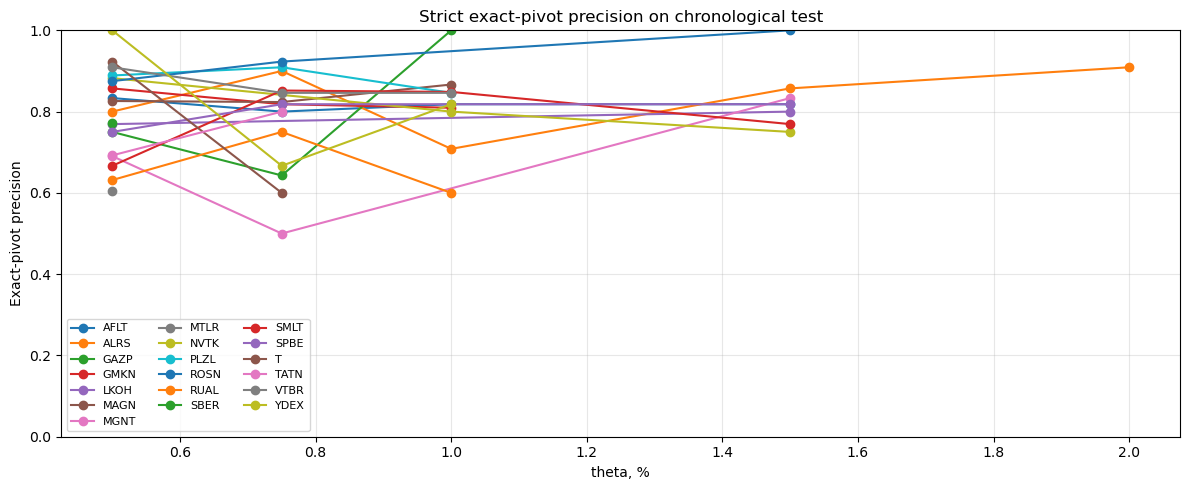

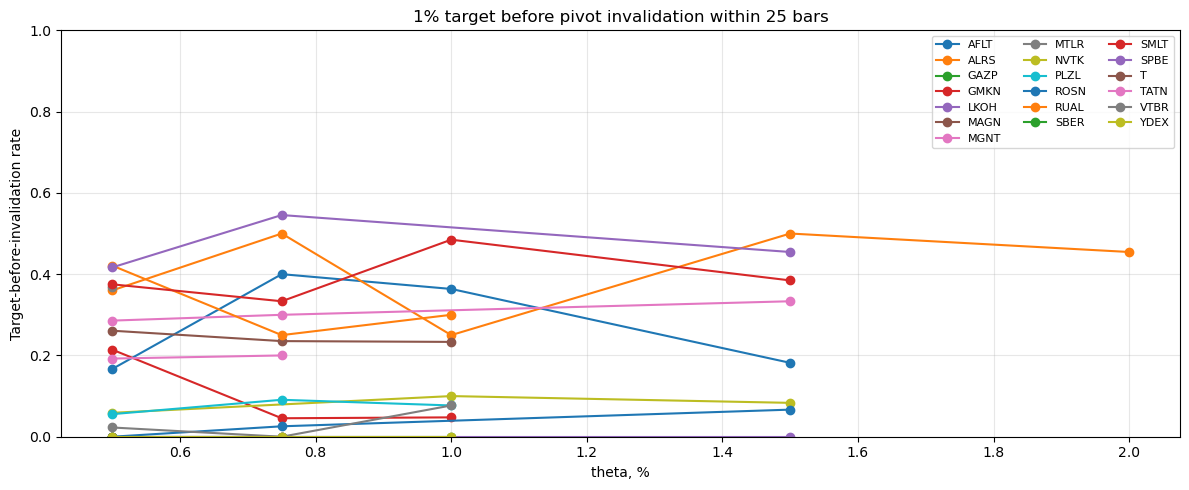

In [8]:
if not summary_df.empty:
    cols = [c for c in [
        "ticker", "theta_%", "n_bars", "dc_events",
        "selected_P_TMV", "selected_P_BM",
        "train_signals", "train_precision_exact_pivot",
        "test_signals", "test_matched", "test_precision_exact_pivot",
        "baseline_test_signals", "baseline_test_precision_exact_pivot",
        "test_target1pct_before_invalidation_25b", "baseline_test_target1pct_before_invalidation_25b",
        "test_median_lead_bars", "status"
    ] if c in summary_df.columns]
    display(summary_df[cols].sort_values(["ticker", "theta_%"]))

    plot_df = summary_df[(summary_df.status == "ok") & (summary_df.test_signals >= 10)]
    if len(plot_df):
        fig, ax = plt.subplots(figsize=(12, 5))
        for ticker, part in plot_df.groupby("ticker"):
            ax.plot(part["theta_%"], part["test_precision_exact_pivot"], marker="o", label=ticker)
        ax.set_title("Strict exact-pivot precision on chronological test")
        ax.set_xlabel("theta, %")
        ax.set_ylabel("Exact-pivot precision")
        ax.set_ylim(0, 1)
        ax.grid(True, alpha=.3)
        ax.legend(ncol=3, fontsize=8)
        plt.tight_layout()
        plt.show()

    target_col = "test_target1pct_before_invalidation_25b"
    if target_col in plot_df and plot_df[target_col].notna().any():
        fig, ax = plt.subplots(figsize=(12, 5))
        for ticker, part in plot_df.groupby("ticker"):
            ax.plot(part["theta_%"], part[target_col], marker="o", label=ticker)
        ax.set_title("1% target before pivot invalidation within 25 bars")
        ax.set_xlabel("theta, %")
        ax.set_ylabel("Target-before-invalidation rate")
        ax.set_ylim(0, 1)
        ax.grid(True, alpha=.3)
        ax.legend(ncol=3, fontsize=8)
        plt.tight_layout()
        plt.show()

## 8. Сохранение результатов

Создаются четыре основных CSV:
- `nowcasting_nca_multiticker_summary_v2.csv` — выбранная конфигурация, строгая метрика и baseline;
- `nowcasting_nca_parameter_grid_v2.csv` — все комбинации параметров;
- `nowcasting_dc_profiles_v2.csv` — профиль DC и корректная оценка амплитуды pivot-to-pivot;
- `nowcasting_nca_signal_details_v2.csv` — сигналы и исходы по каждому событию;
- `nowcasting_ticker_errors_v2.csv` — ошибки загрузки/расчёта, если есть.

Исходные файлы и live-код не меняются.

## 9. Сохранение результатов

CSV сохраняются в `JERICHON/research/nowcasting`. Исходные AlgoPack-файлы и production pipeline не меняются.

In [9]:
OUTPUT_DIR = PROJECT_ROOT / "research" / "nowcasting" / "mark_1" / "results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not summary_df.empty:
    summary_df.to_csv(OUTPUT_DIR / "nowcasting_nca_multiticker_summary_v2.csv", index=False)
if not grid_df.empty:
    grid_df.to_csv(OUTPUT_DIR / "nowcasting_nca_parameter_grid_v2.csv", index=False)
if not dc_profile_df.empty:
    dc_profile_df.to_csv(OUTPUT_DIR / "nowcasting_dc_profiles_v2.csv", index=False)
if not signal_details_df.empty:
    signal_details_df.to_csv(OUTPUT_DIR / "nowcasting_nca_signal_details_v2.csv", index=False)
if not errors_df.empty:
    errors_df.to_csv(OUTPUT_DIR / "nowcasting_ticker_errors_v2.csv", index=False)

print("Saved to:", OUTPUT_DIR)
print("Tickers attempted:", len(TICKERS))
print("Tickers completed:", summary_df.ticker.nunique() if not summary_df.empty and "ticker" in summary_df else 0)
print("Tickers with errors:", len(errors_df))
print("Reminder: strict metrics are exploratory; no live signals deployed.")

Saved to: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\research\nowcasting
Tickers attempted: 19
Tickers completed: 19
Tickers with errors: 0
Reminder: strict metrics are exploratory; no live signals deployed.
